- Business problem:
An e-commerce company struggles to predict how much demand there will be for its products.

- Objective: An e-commerce platform aimed to predict customer demand to optimize pricing and inventory management.

- Approach: Time series data of customer browsing behavior, product views, and historical sales are collected. Multiple models were used to capture seasonality and long-term dependencies.

- Outcome: Accurate demand forecasts helped the e-commerce platform optimize pricing, improve product recommendations, and efficiently manage inventory, resulting in increased sales and customer retention.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r'data/demand.csv')
df.head()

,record_ID,week,store_id,sku_id,total_price,base_price,is_featured_sku,is_display_sku,units_sold
0,1,17/01/11,8091,216418,99.0375,111.8625,0,0,20
1,2,17/01/11,8091,216419,99.0375,99.0375,0,0,28
2,3,17/01/11,8091,216425,133.9500,133.9500,0,0,19
3,4,17/01/11,8091,216233,133.9500,133.9500,0,0,44
4,5,17/01/11,8091,217390,141.0750,141.0750,0,0,52


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150150 entries, 0 to 150149
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   record_ID        150150 non-null  int64  
 1   week             150150 non-null  object 
 2   store_id         150150 non-null  int64  
 3   sku_id           150150 non-null  int64  
 4   total_price      150149 non-null  float64
 5   base_price       150150 non-null  float64
 6   is_featured_sku  150150 non-null  int64  
 7   is_display_sku   150150 non-null  int64  
 8   units_sold       150150 non-null  int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 10.3+ MB


In [6]:
df.describe()

,record_ID,store_id,sku_id,total_price,base_price,is_featured_sku,is_display_sku,units_sold
count,150150.000000,150150.000000,150150.000000,150149.000000,150150.000000,150150.000000,150150.000000,150150.000000
mean,106271.555504,9199.422511,254761.132468,206.626751,219.425927,0.095611,0.133200,51.674206
std,61386.037861,615.591445,85547.306447,103.308516,110.961712,0.294058,0.339792,60.207904
min,1.000000,8023.000000,216233.000000,41.325000,61.275000,0.000000,0.000000,1.000000
25%,53111.250000,8562.000000,217217.000000,130.387500,133.237500,0.000000,0.000000,20.000000
50%,106226.500000,9371.000000,222087.000000,198.075000,205.912500,0.000000,0.000000,35.000000
75%,159452.750000,9731.000000,245338.000000,233.700000,234.412500,0.000000,0.000000,62.000000
max,212644.000000,9984.000000,679023.000000,562.162500,562.162500,1.000000,1.000000,2876.000000


This dataset contains 150150 records in which 51 units sold on an avg. As per the statistics, max to max 2879 units sold on record and minimum 1 unit sold too. This shows how much difference is !!

In [7]:
missing_values = df.isnull().sum()
missing_values

record_ID          0
week               0
store_id           0
sku_id             0
total_price        1
base_price         0
is_featured_sku    0
is_display_sku     0
units_sold         0
dtype: int64

In [3]:
# Missing value
# Calculate median value by grouping to skuid
median_value_per_skuid = df.groupby('sku_id')['total_price'].median()
#print(median_value_per_skuid.value_counts())
# fill the missing values and check it
df['total_price'].fillna(df['sku_id'].map(median_value_per_skuid), inplace=True)

df.isnull().sum()

C:\Users\Asus\AppData\Local\Temp\ipykernel_12724\3585646993.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_price'].fillna(df['sku_id'].map(median_value_per_skuid), inplace=True)


record_ID          0
week               0
store_id           0
sku_id             0
total_price        0
base_price         0
is_featured_sku    0
is_display_sku     0
units_sold         0
dtype: int64

In [4]:
## Convert date column into datetime format

df['week'] = pd.to_datetime(df['week'], format='%d/%m/%y')

## Aggregate the data by week and sum its units sold
weekly_data = df.groupby('week')['units_sold'].sum().reset_index()
weekly_data.head(10)

,week,units_sold
0,2011-01-17,60029
1,2011-01-24,56752
2,2011-01-31,51467
3,2011-02-07,54656
4,2011-02-14,109207
5,2011-02-21,82986
6,2011-02-28,84153
7,2011-03-07,56231
8,2011-03-14,53376
9,2011-03-21,61539


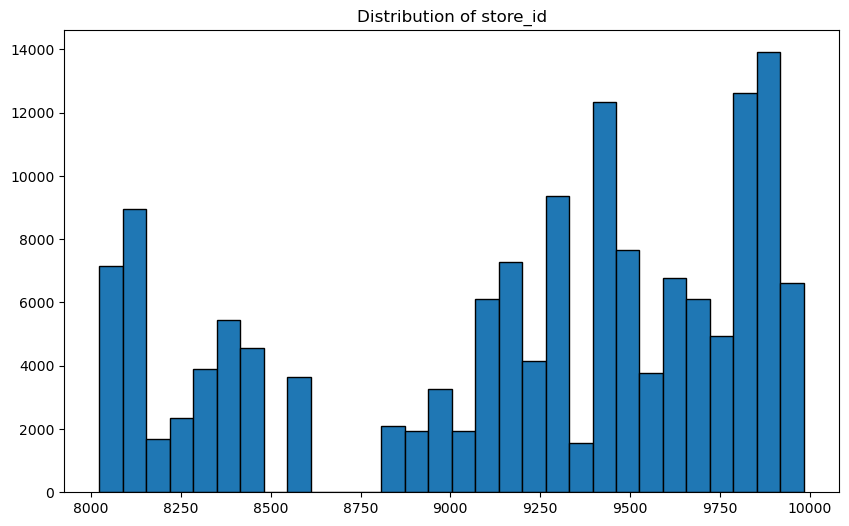

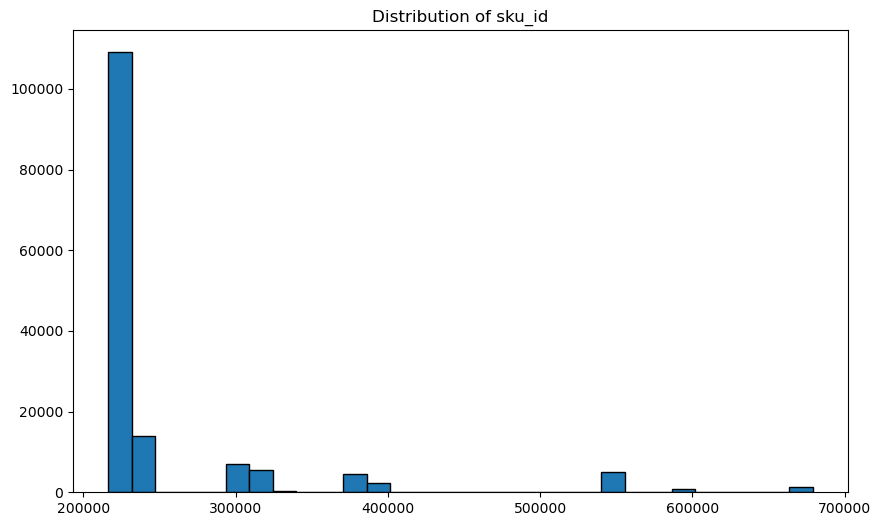

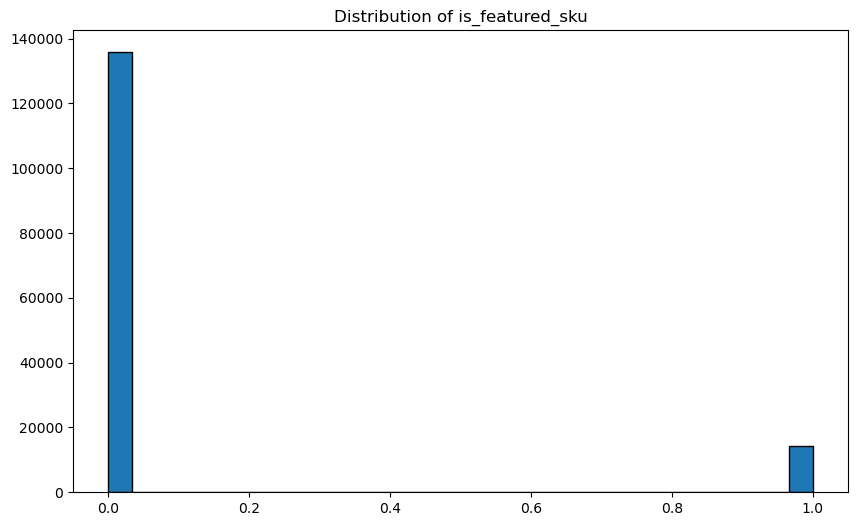

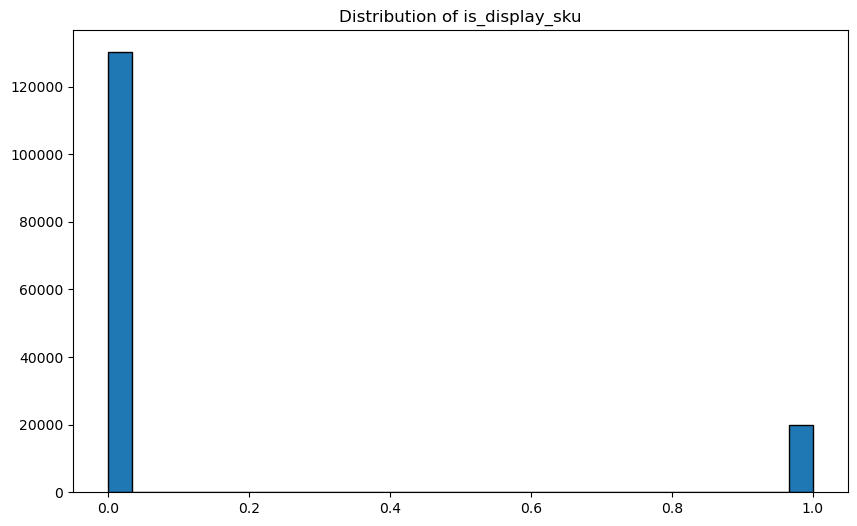

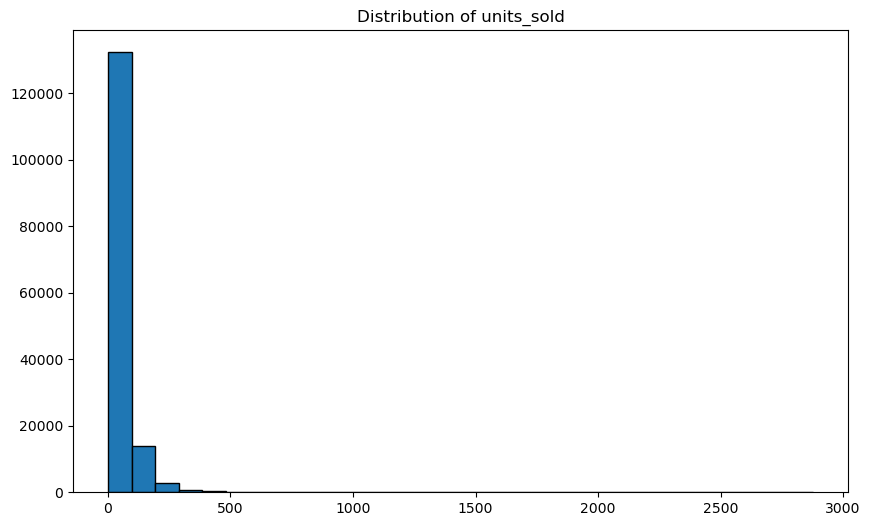

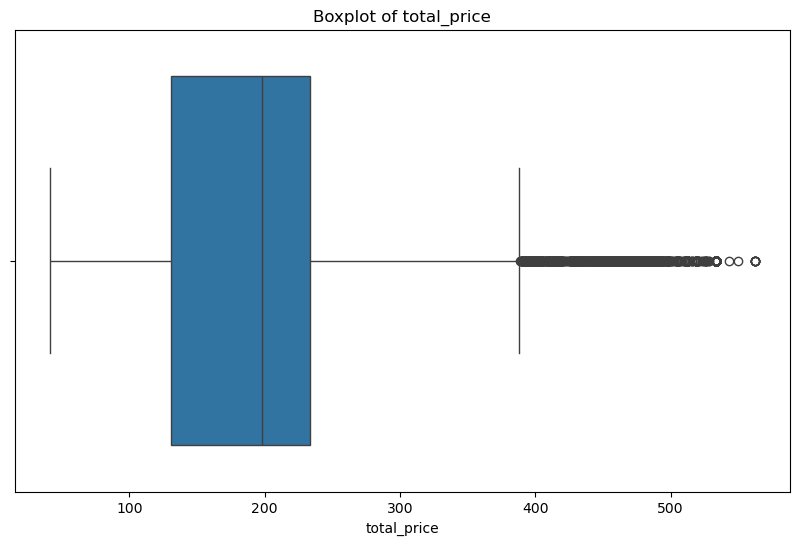

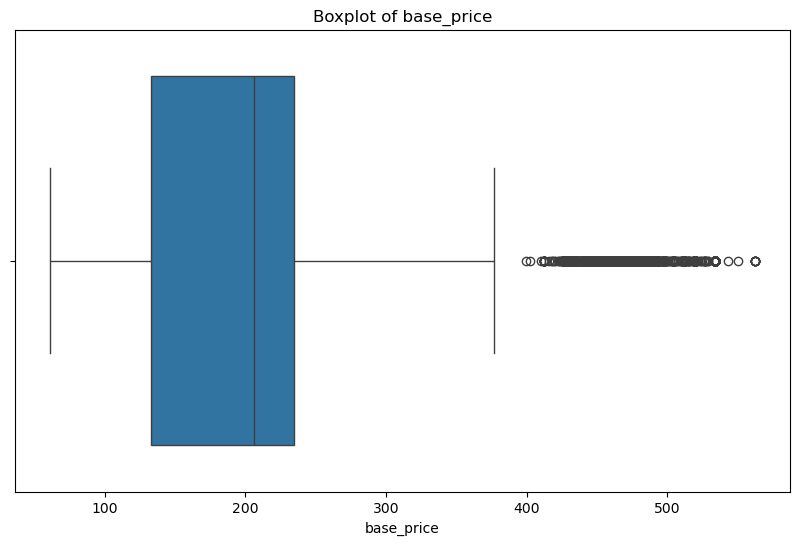

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

#plot histogram of categorical features
categorical_features = ['store_id', 'sku_id', 'is_featured_sku', 'is_display_sku', 'units_sold']

for feature in categorical_features:
    plt.figure(figsize=(10, 6))
    plt.hist(df[feature], bins = 30, edgecolor='black')
    plt.title(f'Distribution of {feature}')
    plt.show()

numerical_features = ['total_price', 'base_price']

for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()

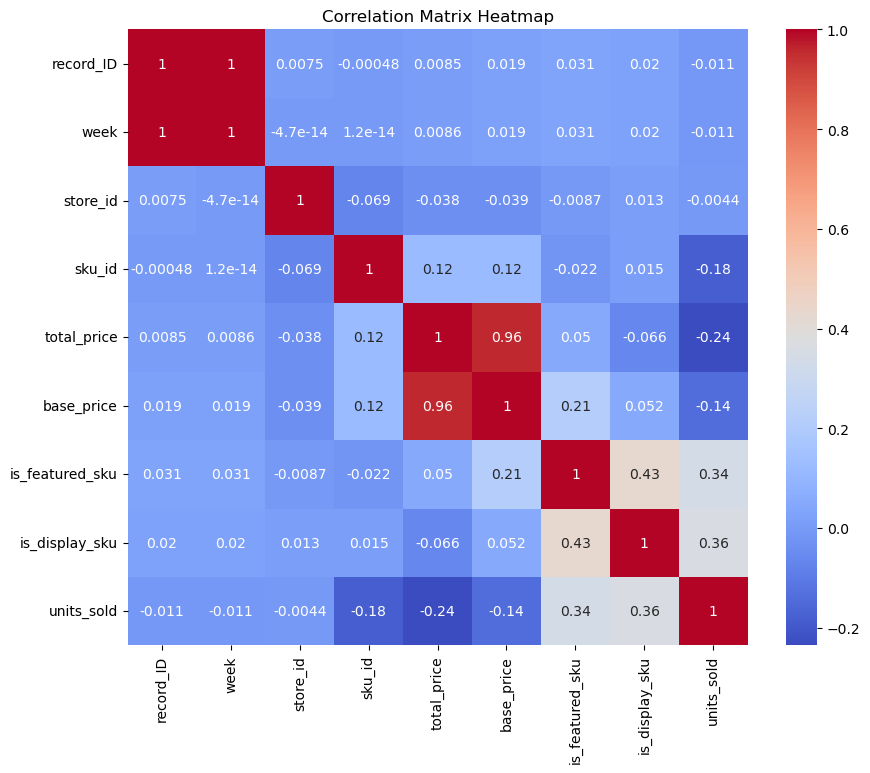

In [8]:
correlation = df.corr()

# Plot a heatmap of the correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()


Base price and total price is highly correlated as total_price = units_sold*base_price.
is_feature_sku is somewhat correlated to is_display_sku as is_feature_sku means is product is promted or not and is_display means displayed on store or not so they are pretty much related.
Then both is_feature_sku and is_display_sku is correlated to units_sold as they affect in promoting sales.

Here are some observations based on the distribution of data and the correlation matrix:

store_id: The distribution shows that the dataset contains data from multiple stores. However, we don't have enough details to make more specific observations about the stores.

sku_id: The distribution suggests that the dataset contains data on multiple SKUs. Similarly, we can't make more specific observations without additional details.

is_featured_sku and is_display_sku: These are binary variables indicating whether the SKU was featured or displayed. The majority of SKUs were neither featured nor displayed.

units_sold: This variable, representing the number of units sold, shows a right-skewed distribution. Most of the values are low, but there are some weeks where a large number of units were sold.

total_price and base_price: These variables represent the total price and base price of the SKUs. There are some outliers, particularly for total price, which may be due to special sales or particularly expensive SKUs.

Looking at the correlation matrix, we see that is_featured_sku and is_display_sku have a moderate positive correlation with units_sold, indicating that when SKUs are featured or displayed, more units tend to be sold. There is also a slight negative correlation between total_price and units_sold, suggesting that lower priced items may sell in higher quantities.

